# Acciones bélicas en Colombia
El corte del 9 de febrero de 2026 contiene **38.333 registros**. 2003 fue el año con más registros (2.812) y Antioquia, el departamento con más (6.743).

Trabajo de Análisis y Visualización de Datos de la Universidad Nacional de Colombia. Equipo académico: Manuela Zapata Jiménez y David Cardona Duque.

## Datos y método
Los CSV contienen agregados de los resultados guardados del notebook original. La unidad es un evento registrado. La fecha completa se valida por separado del año informado. La observación más reciente en el archivo fue del 27 de julio de 2024. [Fuente del CNMH](https://micrositios.centrodememoriahistorica.gov.co/observatorio/portal-de-datos/el-conflicto-en-cifras/acciones-belicas/).

In [1]:
from csv import DictReader
from pathlib import Path

def leer(archivo):
    with (Path('datos') / archivo).open(encoding='utf-8', newline='') as csv:
        return list(DictReader(csv))

def formato(n):
    return f'{n:,}'.replace(',', '.')

class Figura:
    def __init__(self, archivo):
        self.archivo = Path('figuras') / archivo

    def _repr_png_(self):
        return self.archivo.read_bytes()

## Completitud temporal

In [2]:
calidad = {fila['indicador']: int(fila['registros']) for fila in leer('calidad_temporal.csv')}
total = calidad['Fecha completa válida'] + calidad['Sin fecha completa']
assert total == 38_333 and 0 < calidad['Año cero o nulo'] <= calidad['Sin fecha completa']
for indicador, conteo in calidad.items():
    print(f'{indicador}: {formato(conteo)} ({conteo / total:.1%} del total)')

Fecha completa válida: 37.212 (97.1% del total)
Sin fecha completa: 1.121 (2.9% del total)
Año cero o nulo: 220 (0.6% del total)


## Distribución temporal y departamental

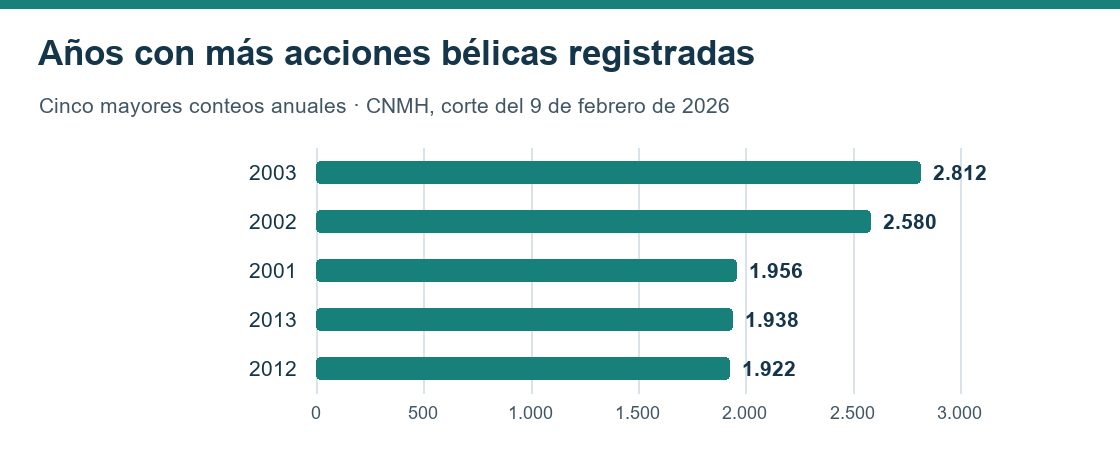

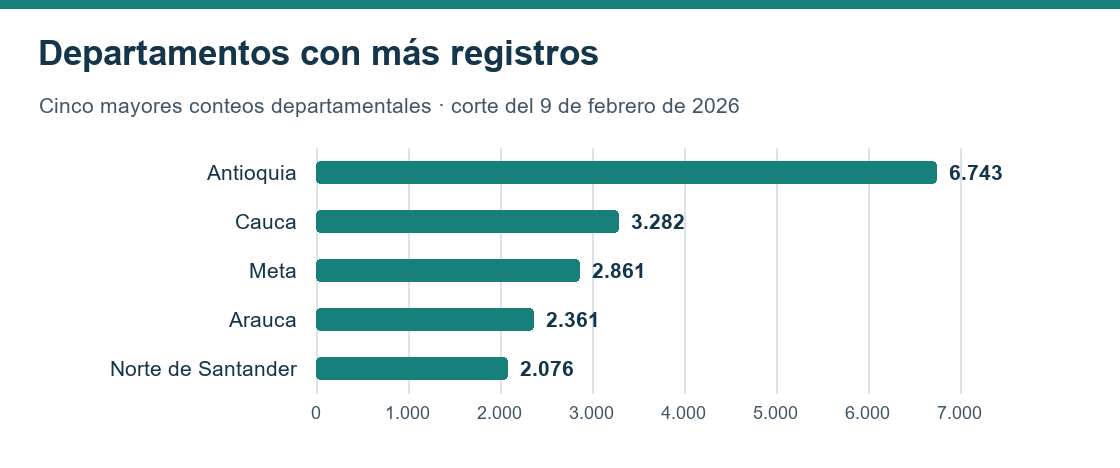

In [3]:
anios = leer('anios_con_mas_registros.csv')
departamentos = leer('departamentos_con_mas_registros.csv')
for serie in (anios, departamentos):
    conteos = [int(fila['registros']) for fila in serie]
    assert conteos == sorted(conteos, reverse=True) and sum(conteos) <= total
display(Figura('anios.png'))
display(Figura('departamentos.png'))

## Interpretación
El ranking compara conteos absolutos del registro. Las diferencias entre departamentos pueden reflejar cobertura, tamaño poblacional y otros factores. La fecha parcial de 2024 limita su comparación con años completos. El script `preparar_datos.py` recalcula agregados a partir de un CSV oficial disponible localmente.